In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

# Locate the project directory
project_dir = Path.cwd()

if not (project_dir / "data" / "raw").exists():
    project_dir = project_dir.parent

raw_dir = project_dir / "data" / "raw"
clean_dir = project_dir / "data" / "clean"
report_dir = project_dir / "report"

print("Project directory:", project_dir)
print("Setup successful!")

Matplotlib is building the font cache; this may take a moment.


Project directory: /Users/malkhyat18/Desktop/clickbait-scorer/clickbait-scorer
Setup successful!


In [2]:
# Load both original datasets
df1 = pd.read_csv(raw_dir / "train1.csv", keep_default_na=False)
df2 = pd.read_csv(raw_dir / "train2.csv", keep_default_na=False)

print("Dataset 1:", df1.shape)
print("Dataset 2:", df2.shape)
print("Total headlines:", len(df1) + len(df2))

print("\nDataset 1 preview:")
display(df1.head())

print("\nDataset 2 preview:")
display(df2.head())

Dataset 1: (32000, 2)
Dataset 2: (21029, 2)
Total headlines: 53029

Dataset 1 preview:


,headline,clickbait
0,Should I Get Bings,1
1,Which TV Female Friend Group Do You Belong In,1
2,"The New ""Star Wars: The Force Awakens"" Trailer...",1
3,"This Vine Of New York On ""Celebrity Big Brothe...",1
4,A Couple Did A Stunning Photo Shoot With Their...,1



Dataset 2 preview:


,label,title
0,news,China and Economic Reform: Xi Jinping’s Track ...
1,news,Trade to Be a Big Topic in Theresa May’s U.S. ...
2,clickbait,"The Top Beaches In The World, According To Nat..."
3,clickbait,Sheriff’s Report Provides New Details on Tamir...
4,news,Surgeon claiming he will transplant volunteer'...


In [3]:
# Standardize column names
data1 = df1.rename(columns={"clickbait": "label"}).copy()
data2 = df2.rename(columns={"title": "headline"}).copy()

# Standardize labels
data1["label"] = pd.to_numeric(data1["label"], errors="coerce")
data2["label"] = data2["label"].map({
    "news": 0,
    "clickbait": 1
})

# Combine both datasets
combined = pd.concat(
    [data1[["headline", "label"]],
     data2[["headline", "label"]]],
    ignore_index=True
)

print("Combined dataset:", combined.shape)
print("\nLabel distribution:")
print(combined["label"].value_counts())

display(combined.head())

Combined dataset: (53029, 2)

Label distribution:
label
0    32739
1    20290
Name: count, dtype: int64


,headline,label
0,Should I Get Bings,1
1,Which TV Female Friend Group Do You Belong In,1
2,"The New ""Star Wars: The Force Awakens"" Trailer...",1
3,"This Vine Of New York On ""Celebrity Big Brothe...",1
4,A Couple Did A Stunning Photo Shoot With Their...,1


In [4]:
# Remove missing headlines and invalid labels
valid = combined.dropna(subset=["headline", "label"]).copy()

# Remove unnecessary whitespace
valid["headline"] = valid["headline"].apply(
    lambda text: " ".join(text.split())
)

valid = valid[valid["headline"] != ""].copy()
valid = valid[valid["label"].isin([0, 1])].copy()
valid["label"] = valid["label"].astype(int)

# Create a normalized key for duplicate detection
def normalize_headline(text):
    text = unicodedata.normalize("NFKC", text)
    return " ".join(text.casefold().split())

valid["normalized_headline"] = valid["headline"].apply(
    normalize_headline
)

print("Invalid rows removed:", len(combined) - len(valid))
print("Remaining headlines:", len(valid))

Invalid rows removed: 0
Remaining headlines: 53029


In [5]:
# Identify headlines with conflicting labels
label_counts = valid.groupby("normalized_headline")["label"].nunique()

conflicting_keys = label_counts[label_counts > 1].index

# Remove all headlines with conflicting labels
conflicting_rows = valid[
    valid["normalized_headline"].isin(conflicting_keys)
]

consistent = valid[
    ~valid["normalized_headline"].isin(conflicting_keys)
].copy()

# Remove remaining duplicate headlines
cleaned = consistent.drop_duplicates(
    subset="normalized_headline",
    keep="first"
).copy()

# Reset the index
cleaned = cleaned.reset_index(drop=True)

# Display cleaning results
print("Original headlines:", len(combined))
print("Conflicting groups:", len(conflicting_keys))
print("Conflicting rows removed:", len(conflicting_rows))
print("Duplicate rows removed:", len(consistent) - len(cleaned))
print("Final cleaned headlines:", len(cleaned))

print("\nFinal label distribution:")
print(cleaned["label"].value_counts())

Original headlines: 53029
Conflicting groups: 25
Conflicting rows removed: 103
Duplicate rows removed: 67
Final cleaned headlines: 52859

Final label distribution:
label
0    32620
1    20239
Name: count, dtype: int64


Class distribution:
label
0    32620
1    20239
Name: count, dtype: int64

Class percentages:
label
0    61.71
1    38.29
Name: proportion, dtype: float64


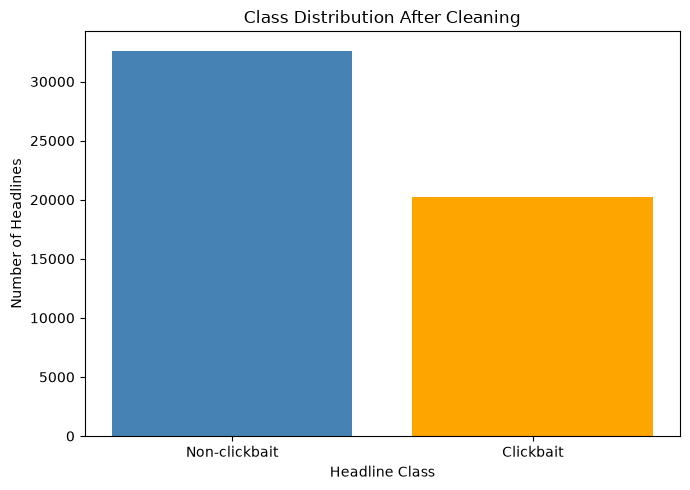

In [6]:
# Analyze class distribution
class_counts = cleaned["label"].value_counts().sort_index()
class_percentages = cleaned["label"].value_counts(
    normalize=True
).sort_index() * 100

print("Class distribution:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages.round(2))

# Visualize class distribution
plt.figure(figsize=(7, 5))

plt.bar(
    ["Non-clickbait", "Clickbait"],
    class_counts.values,
    color=["steelblue", "orange"]
)

plt.title("Class Distribution After Cleaning")
plt.xlabel("Headline Class")
plt.ylabel("Number of Headlines")
plt.tight_layout()
plt.show()

In [13]:
# Analyze headline lengths
cleaned["word_count"] = cleaned["headline"].apply(
    lambda text: len(text.split())
)

print("Average headline length by class:")
print(cleaned.groupby("label")["word_count"].mean().round(2))

print("\nLongest headlines:")
display(cleaned.nlargest(5, "word_count")[
    ["headline", "label", "word_count"]
])

Average headline length by class:
label
0    10.22
1    10.47
Name: word_count, dtype: float64

Longest headlines:


,headline,label,word_count
39169,Top stories Top stories Theresa May delays tri...,1,650
50878,Sections Shows Live Yahoo!-ABC News Network | ...,0,328
38490,Sections Shows Live Yahoo!-ABC News Network | ...,0,327
34081,Sections Shows Live Yahoo!-ABC News Network | ...,0,324
35576,Sections Shows Live Yahoo!-ABC News Network | ...,0,319


In [14]:
# Keep only the columns needed for model training
final_data = cleaned[["headline", "label"]].copy()

# Split into 80% training and 20% temporary data
train, temp = train_test_split(
    final_data,
    test_size=0.2,
    random_state=42,
    stratify=final_data["label"]
)

# Split temporary data into validation and testing
validation, test = train_test_split(
    temp,
    test_size=0.5,
    random_state=42,
    stratify=temp["label"]
)

print("Training:", len(train))
print("Validation:", len(validation))
print("Testing:", len(test))
print("Total:", len(train) + len(validation) + len(test))

Training: 42287
Validation: 5286
Testing: 5286
Total: 52859


In [15]:
# Check for missing values and invalid labels
assert final_data.isnull().sum().sum() == 0
assert final_data["label"].isin([0, 1]).all()

# Check for overlapping headlines between splits
train_keys = set(train["headline"].apply(normalize_headline))
val_keys = set(validation["headline"].apply(normalize_headline))
test_keys = set(test["headline"].apply(normalize_headline))

assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)

assert len(train_keys | val_keys | test_keys) == len(final_data)
assert len(train) + len(validation) + len(test) == len(final_data)

print("All validation checks passed!")
print("No duplicate headlines between splits.")

All validation checks passed!
No duplicate headlines between splits.


In [16]:
# Save cleaned data and final splits
clean_dir.mkdir(parents=True, exist_ok=True)

final_data.to_csv(clean_dir / "cleaned_dataset.csv", index=False)
train.to_csv(clean_dir / "train.csv", index=False)
validation.to_csv(clean_dir / "validation.csv", index=False)
test.to_csv(clean_dir / "test.csv", index=False)

print("All datasets saved successfully!")

All datasets saved successfully!
